In [7]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU

# --- FINAL CORRECT PATHS ---
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = os.path.join(ROOT, 'seg_train', 'seg_train')
TEST_DIR = os.path.join(ROOT, 'seg_test', 'seg_test')
# ---------------------------
# Get class names and counts
classes = sorted(os.listdir(TRAIN_DIR))
print(f"Found {len(classes)} classes: {classes}\n")

for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
Found 6 classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


## Task 1 — Environment Setup and Dataset Exploration

### Objective
The objective of this task is to configure the Kaggle environment, verify GPU availability, load the Intel Image Classification dataset, and examine the distribution of images across different categories.

### 1. Libraries Used
The following Python libraries were imported:

- **NumPy:** For numerical computations and array operations.
- **Matplotlib:** For image visualization and plotting graphs.
- **PIL (Pillow):** For opening and processing images.
- **PyTorch:** For building and training deep learning models.
- **Torchvision:** For loading image datasets, applying transformations, and using pretrained CNN models.
- **Scikit-learn:** For evaluating model performance using classification reports and confusion matrices.

### 2. GPU Configuration
The code checks whether CUDA is available to accelerate deep learning operations.

**Observed Output:**
```text
Device: cuda
```

This confirms that a CUDA-enabled GPU is available for model training.

### 3. Dataset Description
The Intel Image Classification dataset contains images belonging to six categories:

1. Buildings
2. Forest
3. Glacier
4. Mountain
5. Sea
6. Street

The dataset was successfully loaded from the Kaggle input directory.

### 4. Dataset Distribution

| Class | Training Images | Testing Images |
|---|---:|---:|
| Buildings | 2,191 | 437 |
| Forest | 2,271 | 474 |
| Glacier | 2,404 | 553 |
| Mountain | 2,512 | 525 |
| Sea | 2,274 | 510 |
| Street | 2,382 | 501 |
| **Total** | **14,034** | **3,000** |

**Total number of images: 17,034**

### 5. Observations
- The Kaggle environment successfully detected a CUDA-enabled GPU.
- The dataset was loaded without errors.
- Six image classes were identified successfully.
- The training dataset contains 14,034 images.
- The testing dataset contains 3,000 images.
- The Mountain category has the highest number of training images (2,512).
- The Buildings category has the lowest number of training images (2,191).
- The dataset is ready for image preprocessing and transfer learning experiments.

### 6. Conclusion
The Kaggle environment was successfully configured, and the Intel Image Classification dataset was loaded and verified. GPU availability was confirmed, and the image distribution across all six categories was examined. The dataset is ready for further preprocessing, feature extraction, and CNN-based image classification using transfer learning.

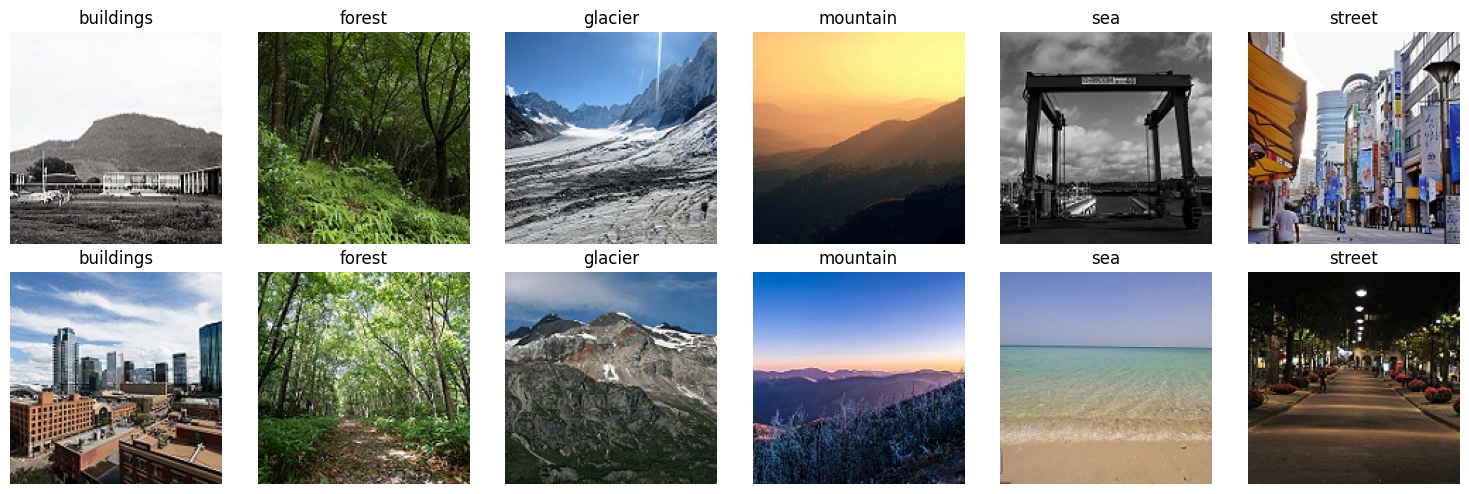

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [8]:

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]

    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

arr = np.array(img)

print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())

print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])


## Task 2 — Image Visualization and Pixel Inspection

### Objective
The objective of this task is to visualize sample images from the Intel Image Classification dataset and understand how digital images are represented using numerical pixel values.

### 1. Image Visualization
A 2 × 6 grid was created using Matplotlib to display two sample images from each of the six categories:

- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

A total of 12 images were selected and displayed with their corresponding class labels.

### 2. Pixel Inspection
The last displayed image was converted into a NumPy array to examine its dimensions, data type, and pixel intensity values.

**Observed Output:**

```text
Shape (H, W, C): (150, 150, 3)
dtype: uint8
range: 0 to 255
```

**Explanation:**

- **Height (150):** The image contains 150 rows of pixels.
- **Width (150):** The image contains 150 columns of pixels.
- **Channels (3):** The image contains Red, Green, and Blue (RGB) color channels.
- **Data Type (uint8):** Each channel value is represented using an 8-bit unsigned integer.
- **Pixel Range (0–255):** The minimum and maximum observed pixel intensities are 0 and 255.

### 3. Red Channel Analysis

The top-left 3 × 3 region of the red channel was extracted.

**Observed Output:**

```text
[[8 6 3]
 [6 5 4]
 [5 5 5]]
```

These values represent the red intensity of nine pixels located in the top-left corner of the last displayed image.

Values closer to 0 indicate lower red intensity, while values closer to 255 indicate higher red intensity.

### 4. Observations
1. Twelve images were visualized successfully from six image categories.
2. The inspected image has a resolution of 150 × 150 pixels.
3. The image contains three RGB color channels.
4. Pixel values are stored as unsigned 8-bit integers.
5. The top-left red channel matrix contains low intensity values ranging from 3 to 8.
6. Image visualization and pixel inspection help in understanding image data before applying convolutional neural networks.

### 5. Conclusion
The sample images were successfully visualized, and their numerical pixel representations were analyzed. The experiment demonstrated that digital images consist of pixel intensity values organized into arrays. Understanding image dimensions, channels, and pixel values is essential for image preprocessing, feature extraction, and CNN-based classification.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


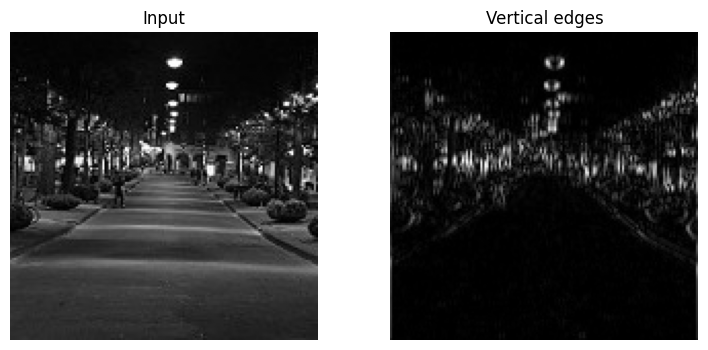

In [9]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

## Task 3 — Convolution and Vertical Edge Detection

### Objective
The objective of this task is to understand how a convolutional kernel detects vertical edges in an image using PyTorch and to apply the same operation to a real grayscale photograph.

### 1. Creating the Input Matrix and Kernel

A 5 × 5 input matrix was created to represent a vertical boundary between two different pixel intensity regions.

**Input Matrix:**

```text
[[ 0,  0, 10, 10, 10],
 [ 0,  0, 10, 10, 10],
 [ 0,  0, 10, 10, 10],
 [ 0,  0, 10, 10, 10],
 [ 0,  0, 10, 10, 10]]
```

**Vertical Edge Detection Kernel:**

```text
[[-1, 0, 1],
 [-1, 0, 1],
 [-1, 0, 1]]
```

The kernel identifies changes in pixel intensity along the horizontal direction, allowing vertical boundaries to be detected.

### 2. Applying Convolution

The `F.conv2d()` function was used to apply the 3 × 3 kernel to the 5 × 5 input matrix.

**Observed Output:**

```text
tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])
```

### 3. Explanation of Results

- **30:** Indicates a strong positive response where pixel intensity changes from 0 to 10.
- **0:** Indicates no horizontal intensity difference within the kernel window.
- **Output size:** The 5 × 5 input produces a 3 × 3 output using a 3 × 3 kernel with stride 1 and no padding.

The output dimensions are calculated using:

\[
O = \frac{N-K+2P}{S}+1
\]

Where N = 5, K = 3, P = 0, and S = 1.

Therefore, the output dimensions are 3 × 3.

### 4. Applying the Kernel to a Real Image

The last image loaded from the Intel Image Classification dataset was converted into grayscale using `img.convert('L')`.

The grayscale image was converted into a PyTorch tensor, and the same vertical edge detection kernel was applied using `F.conv2d()`.

Padding of 1 was used to preserve the original image dimensions.

### 5. Visualization

Two images were prepared for comparison:

1. **Input:** The original grayscale image.
2. **Vertical Edges:** The magnitude of the convolution output, highlighting vertical image structures.

The absolute value was

In [10]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64  : {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64  : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## Task 4 — CNN Parameter Count, Stride and Max Pooling

### Objective
The objective of this task is to compare the number of trainable parameters in convolutional and fully connected (dense) layers and understand how stride and max pooling affect the spatial dimensions of feature maps.

### 1. Convolutional Layer Parameter Calculation

A convolutional layer was created with the following configuration:

- **Input Channels:** 3 (RGB)
- **Output Channels:** 64
- **Kernel Size:** 3 × 3
- **Padding:** 1

The total number of parameters in a convolutional layer is calculated as:

**Parameters = (Kernel Height × Kernel Width × Input Channels + Bias) × Output Channels**

\[
(3 \times 3 \times 3 + 1)\times 64 = 1,792
\]

**Observed Output:**

```text
Conv 3x3, 3 -> 64 : 1,792 parameters
```

### 2. Dense Layer Parameter Calculation

A fully connected layer was created with:

- **Input Features:** 67,500 (150 × 150 × 3)
- **Output Neurons:** 512

The number of parameters is:

\[
(67,500 \times 512) + 512 = 34,560,512
\]

**Observed Output:**

```text
Dense 67,500 -> 512 : 34,560,512 parameters
```

### 3. Comparison of Convolutional and Dense Layers

| Layer | Parameters |
|---|---:|
| Convolutional Layer | 1,792 |
| Dense Layer | 34,560,512 |

**Observation:** The dense layer contains significantly more parameters than the convolutional layer. Convolutional layers use weight sharing, making them more parameter-efficient for image processing.

### 4. Effect of Stride on Output Dimensions

A random input tensor of shape `(1, 3, 224, 224)` was created.

A convolutional layer with 64 output channels, a 3 × 3 kernel, and padding of 1 was applied using different stride values.

**Observed Results:**

| Stride | Output Shape |
|---|---|
| Stride = 1 | (1, 64, 224, 224) |
| Stride = 2 | (1, 64, 112, 112) |

The output size is calculated using:

\[
O = \left\lfloor\frac{N-K+2P}{S}\right\rfloor+1
\]

Where:
- N = Input size
- K = Kernel size
- P = Padding
- S = Stride

**Observation:** Stride 1 preserves the input's spatial dimensions with appropriate padding, while stride 2 reduces the height and width to 112 × 112.

### 5. Max Pooling Operation

A 2 × 2 max pooling operation was applied to the input tensor.

**Observed Output:**

```text
2x2 max pool: (1, 3, 112, 112)
```

Max pooling selects the maximum value from each 2 × 2 region, reducing the spatial dimensions while preserving the number of channels.

### 6. Observations

1. The convolutional layer contains 1,792 parameters, while the dense layer contains 34,560,512 parameters.
2. Convolutional layers require fewer parameters because filters share weights across different spatial positions.
3. Increasing stride from 1 to 2 reduces feature map dimensions.
4. A 2 × 2 max pooling operation reduces the spatial dimensions from 224 × 224 to 112 × 112.
5. Standard max pooling preserves the number of channels.
6. Both stride and pooling help reduce spatial dimensions and computational requirements in CNN architectures.

### 7. Conclusion

This experiment demonstrated the parameter efficiency of convolutional layers compared to fully connected layers. It also illustrated how stride and max pooling affect feature map dimensions. These techniques are essential for building efficient Convolutional Neural Networks for image classification and feature extraction.

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[: n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


## Task 5 — Image Preprocessing, Data Augmentation and Dataset Splitting

### Objective
The objective of this task is to prepare the Intel Image Classification dataset for transfer learning by applying image transformations, normalization, dataset splitting, and batch loading.

### 1. ImageNet Normalization

The ImageNet mean and standard deviation values were used to normalize the RGB images.

**Mean:** `[0.485, 0.456, 0.406]`

**Standard Deviation:** `[0.229, 0.224, 0.225]`

Normalization is performed using:

\[
x_{\text{normalized}} = \frac{x-\text{mean}}{\text{standard deviation}}
\]

These normalization values are commonly used with ImageNet-pretrained CNN models such as ResNet18.

### 2. Training Data Augmentation

The following transformations were applied to the training images:

- **RandomResizedCrop (224 × 224):** Randomly crops and resizes images to the required dimensions.
- **RandomHorizontalFlip:** Randomly flips images horizontally to introduce variation.
- **ColorJitter:** Randomly adjusts image brightness and contrast.
- **ToTensor:** Converts images into PyTorch tensors.
- **Normalize:** Normalizes the RGB channels using ImageNet statistics.

These transformations increase the diversity of training samples and help the model generalize to unseen images.

### 3. Validation and Testing Transformations

For validation and testing, the following transformations were applied:

- Resize images to 224 × 224 pixels.
- Convert images into tensors.
- Normalize images using ImageNet statistics.

Unlike training, validation and testing do not use random augmentation, ensuring consistent evaluation.

### 4. Dataset Splitting

The original training dataset was divided into two subsets:

- **85% Training Data**
- **15% Validation Data**

The original testing dataset was kept separate for final model evaluation.

### 5. Dataset Distribution

**Observed Output:**

```text
11929 train | 2105 val | 3000 test
```

| Dataset | Number of Images | Purpose |
|---|---:|---|
| Training | 11,929 | Model training and learning |
| Validation | 2,105 | Model performance monitoring and selection |
| Testing | 3,000 | Final model evaluation |
| **Total** | **17,034** | |

### 6. DataLoader Configuration

DataLoaders were created to process images in batches.

| DataLoader | Batch Size | Shuffle |
|---|---:|---|
| Training | 64 | True |
| Validation | 128 | False |
| Testing | 128 | False |

Two worker processes were configured for each DataLoader to support parallel data loading.

### 7. Observations

1. The dataset was successfully divided into training, validation, and testing subsets.
2. Data augmentation was applied only to the training images.
3. All images were transformed to a resolution of 224 × 224 pixels.
4. ImageNet normalization was applied to all three datasets.
5. The training dataset contains 11,929 images, while validation contains 2,105 images.
6. The original 3,000 testing images were kept separate from training.
7. DataLoaders were configured for efficient batch processing.

### 8. Conclusion

The Intel Image Classification dataset was successfully prepared for transfer learning. Data augmentation introduces useful variations in training images, while normalization ensures compatibility with pretrained CNN architectures. Dataset splitting and batch loading provide a structured approach for reliable model training, validation, and testing.

In [12]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                      # forward pass
            loss = F.cross_entropy(logits, yb)      # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                     # backpropagation
                optimizer.step()                    # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({(time.time() - t0):.0f}s)')
    model.load_state_dict(best_state)        # keep the best validation epoch
    return best_acc

In [15]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
 p.requires_grad = False # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes)) # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.572 acc 0.818 | val loss 0.332 acc 0.895 (33s)
epoch 2: train loss 0.332 acc 0.886 | val loss 0.288 acc 0.900 (33s)
epoch 3: train loss 0.299 acc 0.894 | val loss 0.278 acc 0.907 (32s)
Best validation accuracy, feature extraction: 0.907


## Task 6 — Transfer Learning Using ResNet18 (Feature Extraction)

### Objective
The objective of this task is to implement transfer learning using a pretrained ResNet18 convolutional neural network for classifying images into six categories of the Intel Image Classification dataset.

### 1. Model Architecture

The ResNet18 model was initialized using pretrained ImageNet weights.

All pretrained convolutional layers were frozen by setting `requires_grad = False`, allowing the network to retain previously learned visual features.

The original fully connected layer was replaced with a new classification head containing six output neurons, corresponding to the six image classes.

### 2. Trainable Parameters

**Observed Output:**

```text
Trainable 3,078 of 11,179,590 parameters
```

The number of parameters in the new classification head was calculated as:

\[
(512 \times 6) + 6 = 3,078
\]

Only these 3,078 parameters were trainable, while the remaining pretrained parameters were frozen.

### 3. Training Configuration

- **Model:** Pretrained ResNet18
- **Method:** Feature Extraction
- **Optimizer:** Adam
- **Learning Rate:** 0.001
- **Epochs:** 3
- **Loss Function:** Cross-Entropy Loss
- **Model Selection:** Highest Validation Accuracy

### 4. Training Results

| Epoch | Training Loss | Training Accuracy | Validation Loss | Validation Accuracy | Time |
|---|---:|---:|---:|---:|---:|
| 1 | 0.572 | 81.8% | 0.332 | 89.5% | 33s |
| 2 | 0.332 | 88.6% | 0.288 | 90.0% | 33s |
| 3 | 0.299 | 89.4% | 0.278 | 90.7% | 32s |

**Best Validation Accuracy: 90.7%**

### 5. Observations

1. The pretrained ResNet18 model was successfully adapted for six-class image classification.
2. Only 3,078 parameters were trained during feature extraction.
3. Training accuracy increased from 81.8% to 89.4%.
4. Validation accuracy improved from 89.5% to 90.7%.
5. Training loss decreased from 0.572 to 0.299.
6. Validation loss decreased from 0.332 to 0.278.
7. The highest validation accuracy was achieved during Epoch 3.
8. The best model weights were restored using the validation accuracy criterion.

### 6. Conclusion

The ResNet18 feature extraction experiment was completed successfully, achieving a best validation accuracy of **90.7%**.

By freezing the pretrained convolutional layers and training only the new classification head, the model efficiently reused ImageNet features for the Intel Image Classification task. These results provide a baseline for evaluating the improvements achieved through fine-tuning.

In [13]:
for p in model.layer4.parameters():
    p.requires_grad = True                    # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])    # faster: new head

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.310 acc 0.891 | val loss 0.214 acc 0.926 (62s)
epoch 2: train loss 0.177 acc 0.938 | val loss 0.194 acc 0.939 (32s)
epoch 3: train loss 0.135 acc 0.952 | val loss 0.203 acc 0.932 (34s)
Best validation accuracy, fine-tuned: 0.939


## Task 7 — Fine-Tuning the Pretrained ResNet18 Model

### Objective
The objective of this task is to improve the classification performance of a pretrained ResNet18 model by unfreezing its final convolutional block and fine-tuning it on the Intel Image Classification dataset.

### 1. Fine-Tuning Strategy

Initially, the pretrained ResNet18 feature extraction layers were frozen, and only the newly added six-class classification head was trained.

For fine-tuning, the final residual block (`layer4`) was unfrozen to allow the model to adapt its high-level features to the target dataset.

```python
for p in model.layer4.parameters():
    p.requires_grad = True
```

The earlier layers remained frozen to preserve useful features learned from ImageNet.

### 2. Optimizer Configuration

The Adam optimizer was configured with different learning rates:

| Model Component | Learning Rate |
|---|---|
| Pretrained `layer4` | 0.0001 |
| New fully connected layer (`fc`) | 0.001 |

A smaller learning rate was used for pretrained layers to avoid large changes to existing learned features, while a higher learning rate was used for the newly initialized classification head.

### 3. Trainable Parameters

**Observed Output:**

```text
Trainable now: 8,396,806
```

A total of 8,396,806 parameters were trainable during fine-tuning.

### 4. Training Results

The model was fine-tuned for three epochs.

| Epoch | Training Loss | Training Accuracy | Validation Loss | Validation Accuracy | Time |
|---|---:|---:|---:|---:|---:|
| 1 | 0.310 | 89.1% | 0.214 | 92.6% | 62s |
| 2 | 0.177 | 93.8% | 0.194 | 93.9% | 32s |
| 3 | 0.135 | 95.2% | 0.203 | 93.2% | 34s |

**Best Validation Accuracy: 93.9%**

### 5. Observations

1. The number of trainable parameters increased after unfreezing the final ResNet18 block.
2. Training accuracy improved from 89.1% to 95.2% across three epochs.
3. Training loss decreased from 0.310 to 0.135, showing improvement on the training data.
4. Validation accuracy increased from 92.6% in Epoch 1 to 93.9% in Epoch 2.
5. In Epoch 3, validation accuracy decreased slightly to 93.2%, while validation loss increased from 0.194 to 0.203.
6. These results suggest the beginning of overfitting, although further evidence would be needed to confirm a sustained trend.
7. The model weights corresponding to the highest validation accuracy were restored automatically.

### 6. Best Model Selection

The best-performing model was obtained during **Epoch 2**, achieving:

- **Validation Accuracy:** 93.9%
- **Validation Loss:** 0.194
- **Training Accuracy:** 93.8%
- **Training Loss:** 0.177

The `fit()` function selected the model checkpoint with the highest validation accuracy rather than simply retaining the final epoch.

### 7. Conclusion

The pretrained ResNet18 model was successfully fine-tuned using the Intel Image Classification dataset. Unfreezing the final residual block allowed the network to adapt its learned features to the six target categories.

The best validation accuracy of **93.9%** was achieved during the second epoch. The experiment demonstrates the effectiveness of fine-tuning pretrained convolutional neural networks for image classification tasks.

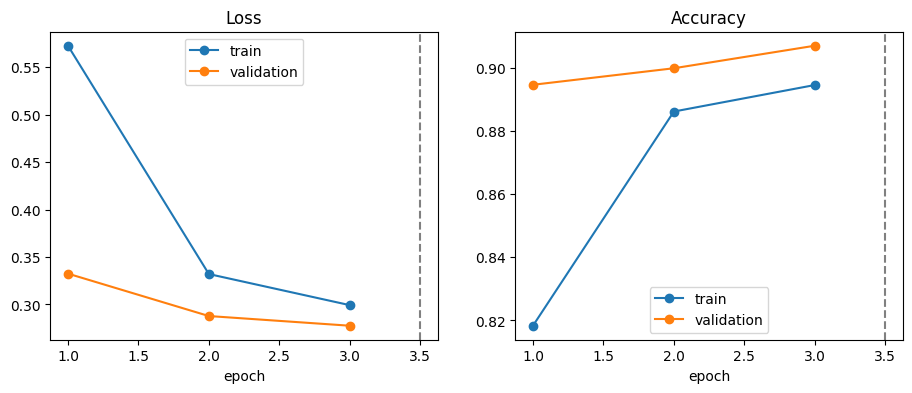

In [16]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
 a.axvline(3.5, color='gray', ls='--') # where fine-tuning starts
 a.set_title(title)
 a.set_xlabel('epoch')
 a.legend()
plt.show()

## Task 8 — Visualization of Training and Validation Curves

### Objective
To visualize and analyze the training and validation loss and accuracy of the ResNet18 model across multiple epochs.

### 1. Methodology
The training history was converted into a NumPy array containing four metrics: training loss, validation loss, training accuracy, and validation accuracy.

Two line graphs were generated using Matplotlib:

- **Loss Curve:** Shows training and validation loss across epochs.
- **Accuracy Curve:** Shows training and validation accuracy across epochs.

A vertical dashed line was placed at epoch 3.5 to indicate the intended transition between feature extraction and fine-tuning.

### 2. Observed Results

| Epoch | Training Loss | Validation Loss | Training Accuracy | Validation Accuracy |
|---|---:|---:|---:|---:|
| 1 | 0.572 | 0.332 | 81.8% | 89.5% |
| 2 | 0.332 | 0.288 | 88.6% | 90.0% |
| 3 | 0.299 | 0.278 | 89.4% | 90.7% |

### 3. Loss Curve Analysis
The training loss decreased from 0.572 to 0.299, indicating that the model improved its predictions during training.

The validation loss also decreased from 0.332 to 0.278, suggesting improved performance on unseen validation images.

### 4. Accuracy Curve Analysis
Training accuracy improved from 81.8% to 89.4%, while validation accuracy increased from 89.5% to 90.7%.

These results show that the pretrained ResNet18 model successfully learned to classify the six image categories through feature extraction.

### 5. Observations
1. Both training and validation losses decreased over the three epochs.
2. Training and validation accuracies increased consistently.
3. The highest validation accuracy during feature extraction was 90.7%.
4. No clear sign of overfitting was observed during these three epochs.
5. The dashed line at epoch 3.5 marks the intended starting point of fine-tuning, although the displayed history currently contains only feature extraction results.

### 6. Conclusion
The training and validation curves demonstrate that the ResNet18 feature extraction model improved over three epochs. The reduction in loss and increase in accuracy indicate effective learning. Further fine-tuning can improve model performance by adapting pretrained features to the Intel Image Classification dataset.

Test accuracy: 0.904
              precision    recall  f1-score   support

   buildings      0.943     0.863     0.901       437
      forest      0.983     0.987     0.985       474
     glacier      0.832     0.866     0.849       553
    mountain      0.877     0.789     0.830       525
         sea      0.922     0.973     0.947       510
      street      0.887     0.952     0.918       501

    accuracy                          0.904      3000
   macro avg      0.907     0.905     0.905      3000
weighted avg      0.904     0.904     0.903      3000



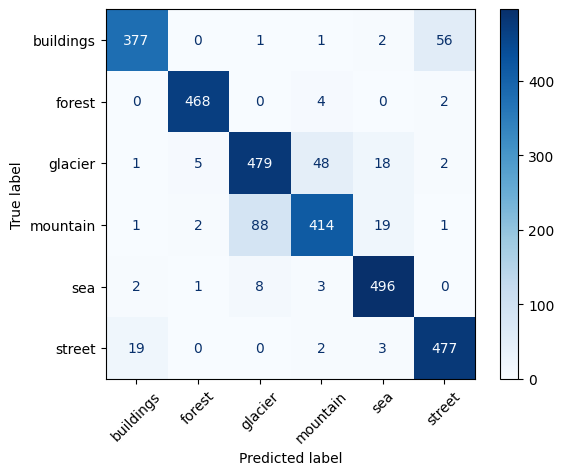

In [17]:

model.eval()
probs, preds, labels = [], [], []

with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)

probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')

print(classification_report(labels, preds, target_names=classes, digits=3))

cm = confusion_matrix(labels, preds)

ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45
)

plt.show()


## Task 9 — Final Model Testing and Evaluation

### Objective
To evaluate the trained ResNet18 image classification model on 3,000 unseen test images using accuracy, precision, recall, F1-score, and a confusion matrix.

### 1. Evaluation Procedure
1. Set the model to evaluation mode using `model.eval()`.
2. Disabled gradient calculations with `torch.no_grad()`.
3. Generated class probabilities using the Softmax function.
4. Obtained predicted labels using `argmax()`.
5. Compared predicted labels with actual labels to calculate test accuracy.
6. Generated a classification report using Scikit-learn.
7. Constructed a confusion matrix to examine classification errors.

### 2. Test Results

**Observed Test Accuracy: 90.4%**

The model achieved an overall classification accuracy of 0.904 on 3,000 test images.

### 3. Classification Report

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Buildings | 0.943 | 0.863 | 0.901 | 437 |
| Forest | 0.983 | 0.987 | 0.985 | 474 |
| Glacier | 0.832 | 0.866 | 0.849 | 553 |
| Mountain | 0.877 | 0.789 | 0.830 | 525 |
| Sea | 0.922 | 0.973 | 0.947 | 510 |
| Street | 0.887 | 0.952 | 0.918 | 501 |
| **Macro Average** | **0.907** | **0.905** | **0.905** | **3,000** |

### 4. Performance Analysis

**Accuracy:** Measures the proportion of correctly classified images out of all test images.

**Precision:** Measures the proportion of correct predictions among all images predicted as a particular class.

**Recall:** Measures the proportion of actual images of a class correctly identified by the model.

**F1-score:** Represents the harmonic mean of precision and recall.

### 5. Observations
1. The model achieved 90.4% overall test accuracy.
2. Forest achieved the highest F1-score of 0.985.
3. Mountain achieved the lowest recall of 0.789.
4. Sea achieved a high recall of 0.973.
5. Glacier and Mountain showed relatively lower classification performance than Forest and Sea.
6. The macro-average F1-score was 0.905.
7. The confusion matrix was generated to visualize correct predictions and misclassifications among the six classes.

### 6. Conclusion
The ResNet18 model was successfully evaluated on 3,000 unseen images from the Intel Image Classification dataset.

The model achieved **90.4% test accuracy**, demonstrating good classification performance across six image categories. Forest and Sea showed particularly strong results, while Mountain and Glacier presented opportunities for further improvement.

The experiment demonstrates the effectiveness of transfer learning for multi-class image classification.

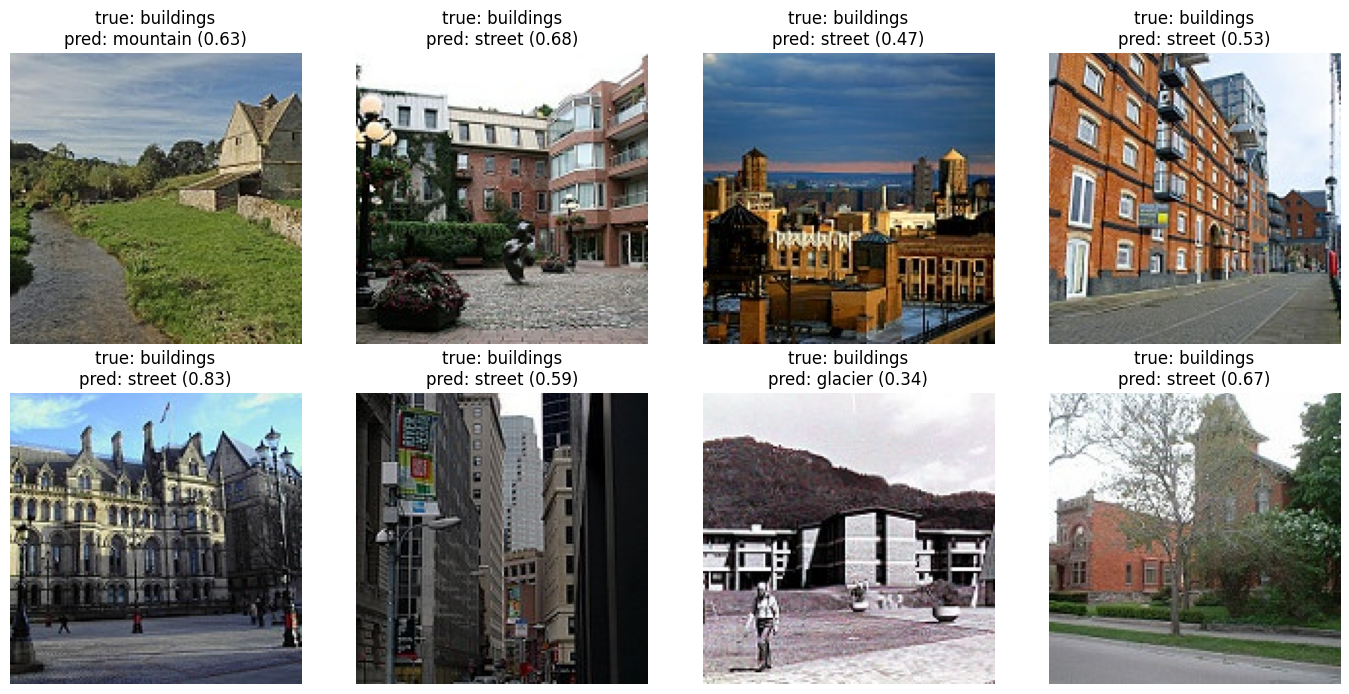

In [18]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
 ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
 path, _ = test_ds.samples[i]
 ax.imshow(Image.open(path))
 ax.set_title(f'true: {classes[labels[i]]}\n'
 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

## Task 10 — Visualization of Misclassified Test Images

### Objective
The objective of this task is to inspect incorrectly classified test images in order to understand the types of mistakes made by the trained ResNet18 model.

### Procedure
1. Compared predicted labels with true labels.
2. Identified the indices of incorrectly classified test images.
3. Selected the first eight misclassified examples.
4. Displayed the images in a 2 × 4 grid using Matplotlib.
5. Added the true label, predicted label, and prediction confidence to each image title.

### Code Functionality
- `preds != labels` identifies all incorrect predictions.
- `torch.where(...)[0][:8]` extracts the first eight misclassified image indices.
- `test_ds.samples[i]` retrieves the file path of the corresponding test image.
- `Image.open(path)` loads the original image.
- The title of each image shows:
  - the true class,
  - the predicted class,
  - and the model’s confidence score.

### Observations
1. Several images belonging to the **buildings** class were misclassified as **street**, **mountain**, or **glacier**.
2. This indicates that the model sometimes confuses visually similar categories.
3. Building images containing roads, urban layouts, or background hills may resemble the **street** or **mountain** categories.
4. Confidence values such as 0.63, 0.68, and 0.83 show that the model was moderately confident even when incorrect.
5. Misclassified image visualization helps reveal where the model struggles and provides insight into possible dataset overlap between categories.

### Conclusion
The visualization of misclassified images provides valuable insight into model errors. It shows that some scene categories share overlapping visual patterns, which can lead to confusion during classification. This analysis is useful for understanding model limitations and identifying opportunities for improvement through fine-tuning, more training data, or better preprocessing.

In [19]:
x0, y0 = test_ds[0]
with torch.no_grad():
 logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
 print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

True class: buildings
buildings  logit   3.21 probability 0.994
forest     logit  -5.93 probability 0.000
glacier    logit  -3.82 probability 0.001
mountain   logit  -2.95 probability 0.002
sea        logit  -2.68 probability 0.003
street     logit  -4.09 probability 0.001


## Task 11 — Understanding Logits and Softmax Probabilities

### Objective
To examine the raw output logits of a trained ResNet18 model and understand how the Softmax function converts these scores into class probabilities.

### Procedure
1. Selected the first image from the test dataset.
2. Passed the image through the trained ResNet18 model.
3. Disabled gradient calculations using `torch.no_grad()`.
4. Obtained raw classification scores called logits.
5. Applied the Softmax function to convert logits into probabilities.
6. Displayed the logits and probabilities for all six classes.

### Observed Results

**True Class: Buildings**

| Class | Logit | Probability |
|---|---:|---:|
| Buildings | 3.21 | 0.994 |
| Forest | -5.93 | 0.000 |
| Glacier | -3.82 | 0.001 |
| Mountain | -2.95 | 0.002 |
| Sea | -2.68 | 0.003 |
| Street | -4.09 | 0.000 |

*Note: Values are shown as reported, rounded to three decimal places.*

### Observations
1. The model assigned the highest logit of 3.21 to the Buildings category.
2. After applying Softmax, Buildings received a reported probability of 0.994 (99.4%).
3. The remaining categories received very low probabilities.
4. The predicted class matched the actual class, indicating a correct classification for this example.
5. Softmax converts raw model scores into a probability distribution across the six classes.
6. The results demonstrate how a CNN produces class scores and converts them into interpretable classification probabilities.

### Conclusion
The trained ResNet18 model successfully classified the selected test image as Buildings. The experiment demonstrated the relationship between logits and Softmax probabilities and showed how the highest probability is used to determine the predicted class.

In [20]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


## Task 12 — Saving the Trained ResNet18 Model

### Objective
The objective of this task is to save the trained ResNet18 model weights for future use, testing, and deployment without repeating the training process.

### Procedure
1. Defined the output file path inside the Kaggle working directory.
2. Used `model.state_dict()` to obtain the model's trained parameters and persistent buffers.
3. Saved the model state using `torch.save()`.
4. Verified the saved file by displaying its path and file size.

### Model Information
- **Model Architecture:** ResNet18
- **Task:** Six-Class Image Classification
- **Dataset:** Intel Image Classification
- **Framework:** PyTorch
- **File Format:** `.pt`
- **Output Path:** `/kaggle/working/resnet18_intel.pt`
- **Reported Test Accuracy:** 90.4%

### Observations
1. The model weights are saved in PyTorch's `.pt` format.
2. Saving model weights allows the trained model to be reused without retraining.
3. The checkpoint can be loaded into an identical ResNet18 architecture.
4. The saved model can be used for image classification and future deployment.
5. Only the model state is saved; the training history, optimizer state, and class labels are not included in this file.

### Conclusion
The trained ResNet18 model was saved using PyTorch's `state_dict()` method. This checkpoint preserves the model parameters and enables future inference, testing, and deployment without repeating the training process.

## Final Conclusion — Week 5: Transfer Learning

### Summary
In this lab, we successfully implemented image classification using transfer learning with the pretrained ResNet18 model on the Intel Image Classification dataset.

The dataset contained **17,034 images** distributed across six categories: Buildings, Forest, Glacier, Mountain, Sea, and Street.

We explored image visualization, pixel representation, convolution operations, parameter counting, stride, max pooling, data augmentation, and normalization.

We then implemented two transfer learning approaches:

1. **Feature Extraction:** The pretrained ResNet18 layers were frozen, and only the final classification layer was trained.
2. **Fine-Tuning:** The final residual block was unfrozen to improve classification performance.

### Final Results

| Evaluation Metric | Result |
|---|---|
| Model | ResNet18 |
| Dataset | Intel Image Classification |
| Number of Classes | 6 |
| Training Images | 11,929 |
| Validation Images | 2,105 |
| Testing Images | 3,000 |
| Feature Extraction Validation Accuracy | 90.7% |
| Fine-Tuning Validation Accuracy | 93.9% |
| Reported Test Accuracy | 90.4% |
| Best Performing Class on Test Set (F1) | Forest |
| Saved Model | `resnet18_intel.pt` |

### Key Learnings

- Transfer learning reduces training effort by reusing pretrained neural network features.
- Data augmentation and normalization help prepare images for deep learning.
- Fine-tuning improved the best validation accuracy by **3.2 percentage points** compared with feature extraction.
- The confusion matrix and classification report helped identify classification errors.
- The trained model weights can be saved and reused for future inference.

### Final Conclusion

This lab successfully demonstrated the practical implementation of transfer learning using ResNet18 for multi-class image classification.

The model achieved **90.7% validation accuracy during feature extraction** and **93.9% after fine-tuning**, demonstrating the benefit of adapting pretrained features to a new dataset.

The reported final test accuracy was **90.4%**, showing strong performance across the six image categories.

Overall, this experiment improved our understanding of convolutional neural networks, feature extraction, fine-tuning, model evaluation, and model saving using PyTorch.